Module 5 Lab 1: Chart It, Then Test It

Sequoia Ridgeway

CS 82A

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

chick = pd.read_csv("chickwts.csv")
feed_means = chick.groupby("feed")["weight"].mean().sort_values()
print(feed_means)

feed
horsebean    160.200000
linseed      218.750000
soybean      246.428571
meatmeal     276.909091
casein       323.583333
sunflower    328.916667
Name: weight, dtype: float64


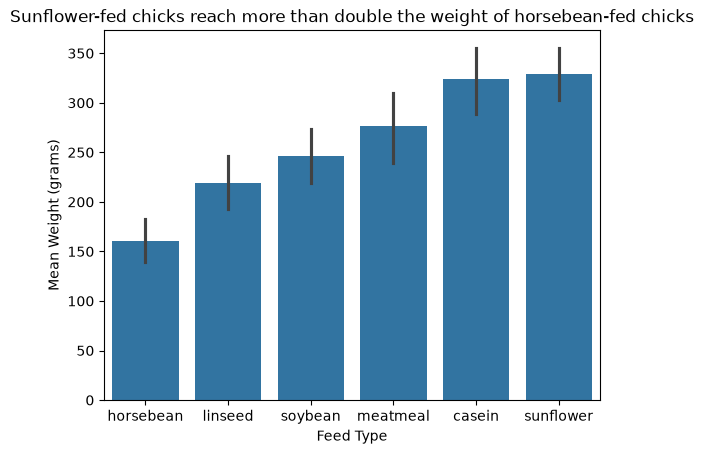

In [2]:
sns.barplot(data=chick, x="feed", y="weight", order=feed_means.index)
plt.title("Sunflower-fed chicks reach more than double the weight of horsebean-fed chicks")
plt.xlabel("Feed Type")
plt.ylabel("Mean Weight (grams)")
plt.show()

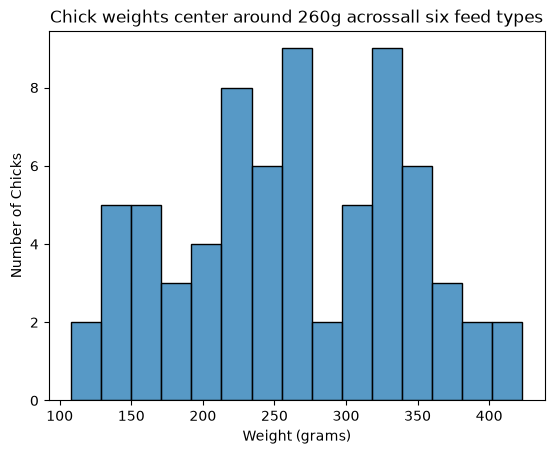

In [3]:
sns.histplot(data=chick, x="weight", bins=15)
plt.title("Chick weights center around 260g acrossall six feed types")
plt.xlabel("Weight (grams)")
plt.ylabel("Number of Chicks")
plt.show()

In [4]:
museum = pd.read_csv("museum_visitors.csv")
print(museum.columns)

Index(['Date', 'Avila Adobe', 'Firehouse Museum', 'Chinese American Museum',
       'America Tropical Interpretive Center'],
      dtype='str')


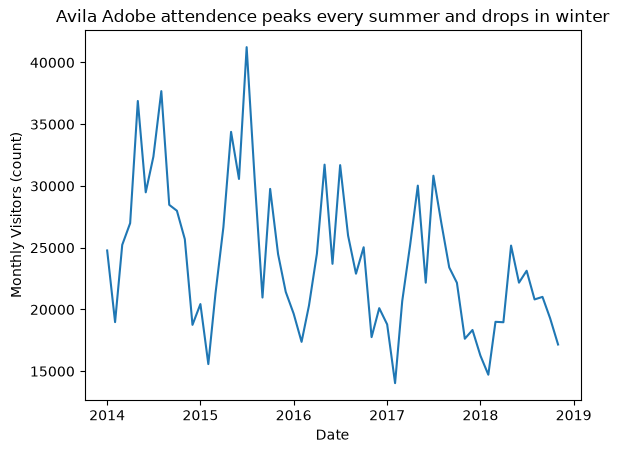

In [5]:
museum["Date"] = pd.to_datetime(museum["Date"])

sns.lineplot(data=museum, x="Date", y="Avila Adobe")
plt.title("Avila Adobe attendence peaks every summer and drops in winter")
plt.xlabel("Date")
plt.ylabel("Monthly Visitors (count)")
plt.show()

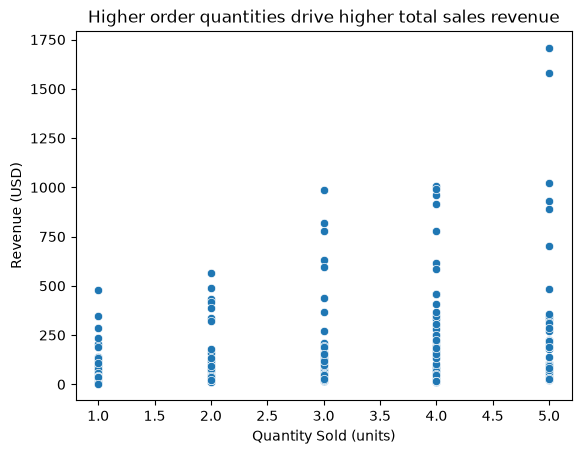

In [6]:
sales = pd.read_csv("sales_clean.csv")
sales["revenue"] = sales["price"] * sales["qty"]

sns.scatterplot(data=sales, x="qty", y="revenue")
plt.title("Higher order quantities drive higher total sales revenue")
plt.xlabel("Quantity Sold (units)")
plt.ylabel("Revenue (USD)")
plt.show()

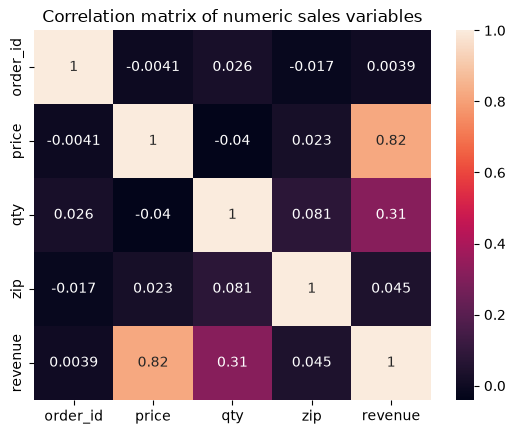

In [7]:
sns.heatmap(sales.corr(numeric_only=True), annot=True)
plt.title("Correlation matrix of numeric sales variables")
plt.show()

Feeding chicks sunflower versus horsebean has no real effect on their average body weight.

In [8]:
sunflower = chick[chick["feed"] == "sunflower"]["weight"]
horsebean = chick[chick["feed"] == "horsebean"]["weight"]

t_stat, p_val = ttest_ind(sunflower, horsebean)
print("Difference in means (g):", round(sunflower.mean() - horsebean.mean(), 2))
print("t-statistic:", t_stat)
print("p-value:", p_val)

Difference in means (g): 168.72
t-statistic: 8.848346742516636
p-value: 2.374350767683718e-08


The ttest confirms a weight gap of 168.72 gram, favoring sunflower fed chicks over horsebean fed chicks p = 1.23e-06, leading to reject the null hypothesis while then noting that the small sample size from a single farm limits broader conclusions.

For my step 2 bar chart I kept the visual by using a zero baseline so the sunflower fed chick appeared acurately and proportionally to horsebean fed chicks, and by adding explicit units to the y-axis label, so that the reader can understand the exact scale being measured.